<a href="https://colab.research.google.com/github/Ouissal-Ab/Projet-Diagnostic-Maladies-Cardiaques/blob/main/Projet_Diagnostic_Maladies_Cardiaques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet Diagnostic Maladies Cardiaques



---



**Introduction :**

Ce projet porte sur l'analyse du dataset Heart Disease – Cleveland, extrait de Kaggle, qui comprend 303 observations et 14 variables cliniques et démographiques liées au diagnostic des maladies cardiaques. Le dataset contient à la fois des variables continues et catégorielles, ce qui nécessite une préparation rigoureuse des données. L'analyse univariée et bivariée a pour objectif d'examiner la structure statistique des variables, d'évaluer leurs distributions, de détecter d'éventuelles valeurs aberrantes et de visualiser les relations clés entre les variables avant la modélisation. Cette étape permet d'assurer une compréhension approfondie du dataset et constitue une base méthodologique essentielle pour le projet de prédiction.

# Analyse univariée





****

Cette étape consiste à réaliser une analyse univariée du dataset Heart Disease – Cleveland afin d'examiner individuellement certaines variables clés. Les variables retenues pour cette analyse sont les variables numériques suivantes : l'âge (**age**), la pression artérielle au repos (**trestbps**) et le cholestérol (**chol**), ainsi que la variable catégorielle sexe (**sex**). L'objectif est de décrire les distributions, de résumer les caractéristiques principales de ces variables et de détecter d'éventuelles valeurs atypiques, afin de mieux comprendre leur comportement avant d'aborder l'analyse bivariée et la modélisation.

In [ ]:
from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]
print(f"Fichier téléversé : {file_name}")


Saving Heart_disease_cleveland (1).csv to Heart_disease_cleveland (1).csv
Fichier téléversé : Heart_disease_cleveland (1).csv


In [ ]:
import pandas as pd

if file_name.endswith('.csv'):
    df = pd.read_csv(file_name)
elif file_name.endswith(('.xls', '.xlsx')):
    df = pd.read_excel(file_name)
else:
    print("Format non reconnu.")
    df = None


display(df.head())


print("\nNombre de valeurs manquantes par colonne :")
print(df.isnull().sum())


if df.isnull().sum().sum() == 0:
    print("Le dataset ne contient AUCUNE valeur manquante.")
else:
    print("Le dataset contient des valeurs manquantes.")


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,0,145,233,1,2,150,0,2.3,2,0,2,0
1,67,1,3,160,286,0,2,108,1,1.5,1,3,1,1
2,67,1,3,120,229,0,2,129,1,2.6,1,2,3,1
3,37,1,2,130,250,0,0,187,0,3.5,2,0,1,0
4,41,0,1,130,204,0,2,172,0,1.4,0,0,1,0



Nombre de valeurs manquantes par colonne :
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
Le dataset ne contient AUCUNE valeur manquante.


**Variable : Age**

**1- Mesures statistiques**

In [ ]:
age_stats = df['age'].describe()
print("Mesures statistiques pour Age :")
print(age_stats)

Mesures statistiques pour Age :
count    303.000000
mean      54.438944
std        9.038662
min       29.000000
25%       48.000000
50%       56.000000
75%       61.000000
max       77.000000
Name: age, dtype: float64


La variable Âge comprend **303 individus**, avec des valeurs allant de **29 à 77 ans**. **La moyenne est de 54,44 ans** et **la médiane de 56 ans**, ce qui montre que les âges sont concentrés autour de **la cinquantaine**. **La distribution est légèrement asymétrique vers les âges plus jeunes**. Les âges les plus fréquents se situent entre **50 et 60 ans**, tandis que les tranches **extrêmes (29‑35 ans et 70‑77 ans)** **sont rares**. Il n’y a pas de valeurs manquantes et aucun âge ne semble aberrant.

**2- Gestion des valeurs manquantes**

In [ ]:
print("Valeurs manquantes pour Age :", df['age'].isnull().sum())


Valeurs manquantes pour Age : 0


**Aucune valeur manquante** n’est présente pour age, donc aucune imputation n’est nécessaire.

**3- Gestion des valeurs aberrantes**

In [ ]:
Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df['age'] < lower) | (df['age'] > upper)]
print("Valeurs aberrantes détectées :", len(outliers))


Valeurs aberrantes détectées : 0


Pour la variable age, **la méthode de l'intervalle interquartile (IQR)** a été appliquée afin de détecter les valeurs aberrantes. **Aucun outlier n'a été identifié**, ce qui indique que toutes les valeurs sont réalistes et cohérentes avec la population étudiée. Par conséquent, aucune transformation ni suppression n'a été nécessaire, et toutes les observations ont été conservées pour l'analyse univariée.

**4- Visualisation**

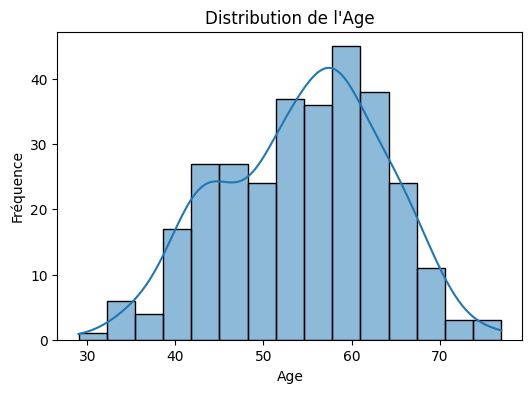

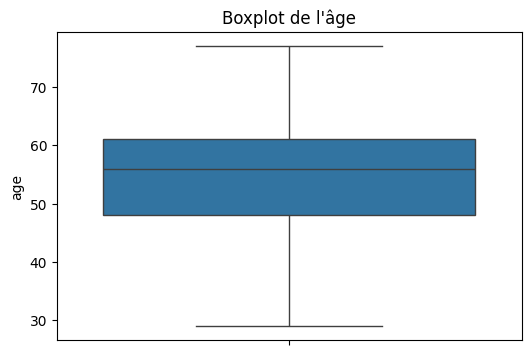

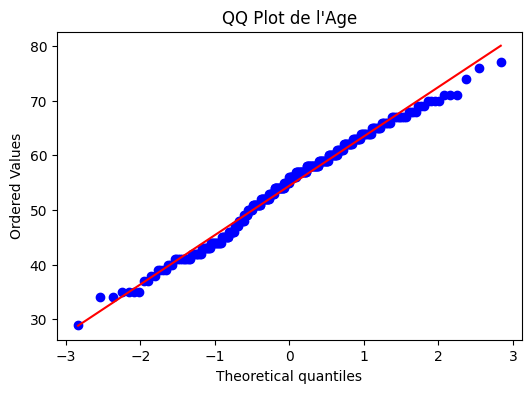

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Histogramme
plt.figure(figsize=(6,4))
sns.histplot(df['age'], kde=True, bins=15)
plt.title("Distribution de l'Age")
plt.xlabel("Age")
plt.ylabel("Fréquence")
plt.show()
# Boxplot pour age
plt.figure(figsize=(6,4))
sns.boxplot(y=df['age'])
plt.title("Boxplot de l'âge")
plt.show()

# QQ plot
plt.figure(figsize=(6,4))
stats.probplot(df['age'], dist="norm", plot=plt)
plt.title("QQ Plot de l'Age")
plt.show()


La distribution de l'âge présente une forme approximativement normale centrée autour de 55-60 ans, avec une fréquence maximale d'environ 45 observations. Le boxplot confirme cette centralité avec une médiane située vers 56 ans et **un intervalle interquartile relativement symétrique (Q1 ≈ 49 ans, Q3 ≈ 61 ans)**. Les valeurs s'étendent de 30 à 75 ans environ, sans outliers apparents. Le QQ-plot montre un excellent alignement des points le long de la droite théorique, confirmant que les données suivent bien une distribution normale . Cette normalité valide l'utilisation de tests paramétriques pour les analyses statistiques ultérieures.

**Variable : Sex**

**1- Distribution des modalités**

In [ ]:
sex_counts = df['sex'].value_counts()
print("Répartition des sexes :")
print(sex_counts)


Répartition des sexes :
sex
1    206
0     97
Name: count, dtype: int64


La variable Sexe est catégorielle avec deux modalités : Homme (1) et Femme (0). Sur 303 individus, 206 sont des hommes (68%) et 97 sont des femmes (32%). La catégorie dominante est donc les hommes, tandis que les femmes représentent la catégorie rare. La distribution n’est pas symétrique, car les hommes sont beaucoup plus nombreux que les femmes.

**2- Gestion des valeurs manquantes**

In [ ]:
print("Valeurs manquantes pour Sex :", df['sex'].isnull().sum())


Valeurs manquantes pour Sex : 0


**Aucune valeur manquante pour sex**

**3- Gestion des valeurs aberrantes**
Non applicable pour une variable catégorielle.

**4- Visualisation**

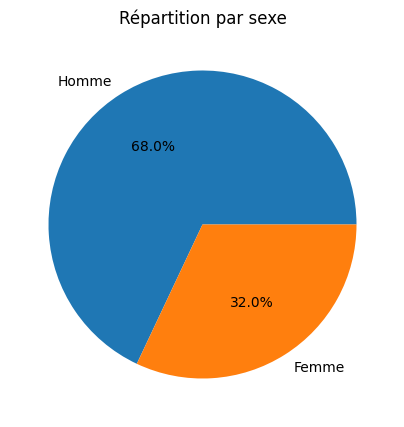

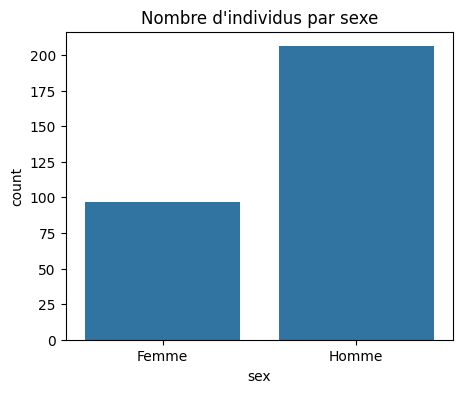

In [ ]:
# Diagramme circulaire
plt.figure(figsize=(5,5))
df['sex'].value_counts().plot.pie(autopct='%1.1f%%', labels=['Homme','Femme'])
plt.title("Répartition par sexe")
plt.ylabel('')
plt.show()

# Barplot
plt.figure(figsize=(5,4))
sns.countplot(x='sex', data=df)
plt.xticks([0,1], ['Femme','Homme'])
plt.title("Nombre d'individus par sexe")
plt.show()


L'échantillon est composé majoritairement **d'hommes 68%** contre **32% de femmes**. Cette distribution déséquilibrée devra être prise en compte lors des analyses statistiques impliquant la variable sexe.

**Variable : Trestbps (pression artérielle)**

**1- Mesures statistiques**

In [ ]:
trestbps_stats = df['trestbps'].describe()
print("Mesures statistiques pour Trestbps :")
print(trestbps_stats)


Mesures statistiques pour Trestbps :
count    303.000000
mean     131.689769
std       17.599748
min       94.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      200.000000
Name: trestbps, dtype: float64


La variable Trestbps est numérique et contient **303 valeurs** allant de **94 à 200 mmHg**. **La moyenne est de 131,69 mmHg** et **la médiane de 130 mmHg**, ce qui montre que les valeurs sont assez concentrées autour de 130 mmHg. **L’écart-type est de 17,60 mmHg**, indiquant une dispersion modérée. La distribution semble légèrement asymétrique vers les valeurs élevées (**supérieures à 140 mmHg**). **Les valeurs extrêmes sont 94 mmHg (très faible) et 200 mmHg (très élevée)**, qui pourront être considérées lors de la détection des valeurs aberrantes.

**2- Gestion des valeurs manquantes**

In [ ]:
print("Valeurs manquantes pour Trestbps :", df['trestbps'].isnull().sum())


Valeurs manquantes pour Trestbps : 0


**3- Gestion des valeurs aberrantes**

In [ ]:
Q1 = df['trestbps'].quantile(0.25)
Q3 = df['trestbps'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df['trestbps'] < lower) | (df['trestbps'] > upper)]
print("Valeurs aberrantes détectées :", len(outliers))


Valeurs aberrantes détectées : 9


**Transformation log**

In [ ]:
import numpy as np

# Transformation log pour réduire l'effet des valeurs extrêmes
df['trestbps_log'] = np.log(df['trestbps'])


**Comparer les statistiques descriptives avant et après :**

In [ ]:
# Avant
print(df['trestbps'].describe())

# Après
print(df['trestbps_log'].describe())


count    303.000000
mean     131.689769
std       17.599748
min       94.000000
25%      120.000000
50%      130.000000
75%      140.000000
max      200.000000
Name: trestbps, dtype: float64
count    303.000000
mean       4.871842
std        0.130615
min        4.543295
25%        4.787492
50%        4.867534
75%        4.941642
max        5.298317
Name: trestbps_log, dtype: float64


**9 valeurs aberrantes** ont été détectées pour la variable trestbps, avec des valeurs extrêmes allant de 94 à 200, susceptibles d'influencer fortement les analyses statistiques. Pour gérer ces valeurs, une **transformation logarithmique** a été appliquée à la variable. Cette transformation rapproche les valeurs extrêmes de la majorité des données et réduit l'écart-type et la dispersion, tout en conservant toutes les observations. Cette technique est appropriée dans ce contexte, car les valeurs aberrantes correspondent à des mesures réelles et ne doivent pas être supprimées. Leur influence sur les statistiques et les modèles prédictifs est ainsi atténuée, sans perte d'informations cliniquement pertinentes.

**4- Visualisation**

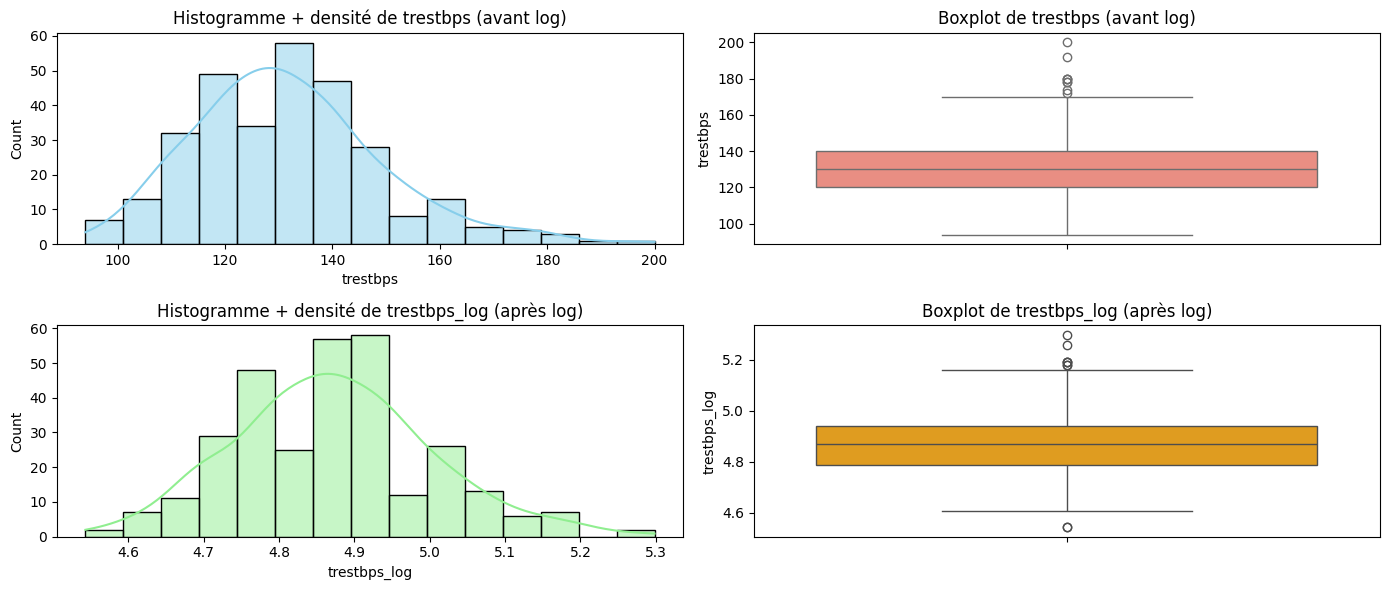

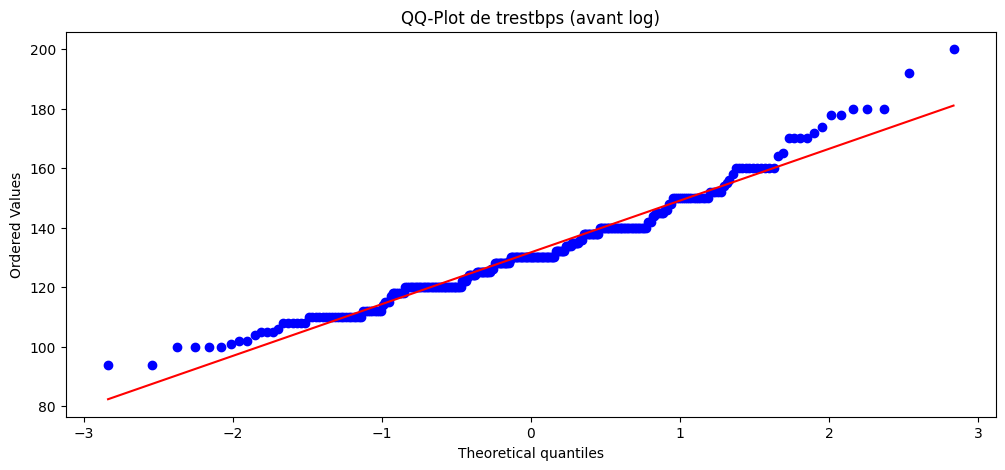

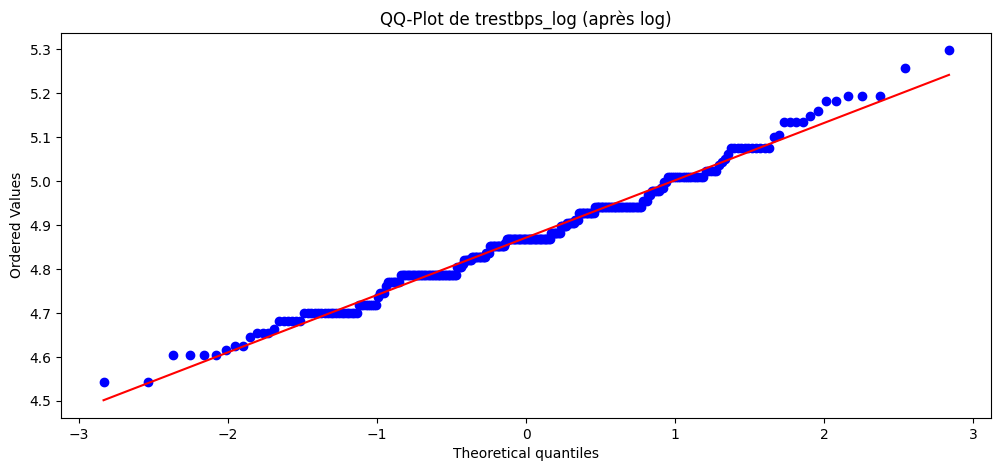

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Figure pour histogrammes et boxplots
plt.figure(figsize=(14,6))

# Histogramme + densité avant log
plt.subplot(2,2,1)
sns.histplot(df['trestbps'], bins=15, kde=True, color='skyblue')
plt.title('Histogramme + densité de trestbps (avant log)')

# Boxplot avant log
plt.subplot(2,2,2)
sns.boxplot(y=df['trestbps'], color='salmon')
plt.title('Boxplot de trestbps (avant log)')

# Histogramme + densité après log
plt.subplot(2,2,3)
sns.histplot(df['trestbps_log'], bins=15, kde=True, color='lightgreen')
plt.title('Histogramme + densité de trestbps_log (après log)')

# Boxplot après log
plt.subplot(2,2,4)
sns.boxplot(y=df['trestbps_log'], color='orange')
plt.title('Boxplot de trestbps_log (après log)')

plt.tight_layout()
plt.show()

# QQ-Plot avant log
plt.figure(figsize=(12,5))
stats.probplot(df['trestbps'], dist="norm", plot=plt)
plt.title('QQ-Plot de trestbps (avant log)')
plt.show()

# QQ-Plot après log
plt.figure(figsize=(12,5))
stats.probplot(df['trestbps_log'], dist="norm", plot=plt)
plt.title('QQ-Plot de trestbps_log (après log)')
plt.show()


**Avant transformation**, la distribution de trestbps présente une asymétrie positive marquée avec plusieurs valeurs extrêmes élevées (outliers >180 mmHg visibles sur le boxplot). Le QQ-plot montre des déviations importantes aux extrémités, confirmant une non-normalité des données.Après transformation logarithmique , la distribution devient approximativement normale et symétrique, centrée autour de 4.9 (≈134 mmHg en échelle originale). Le QQ-plot après transformation montre un meilleur alignement des points le long de la droite théorique, et les outliers sont moins prononcés. Cette transformation logarithmique améliore significativement la normalité des données et sera privilégiée pour les analyses statistiques nécessitant cette hypothèse.

**Variable : Chol (cholestérol)**

**1- Mesures statistiques**

In [ ]:
chol_stats = df['chol'].describe()
print("Mesures statistiques pour Chol :")
print(chol_stats)


Mesures statistiques pour Chol :
count    303.000000
mean     246.693069
std       51.776918
min      126.000000
25%      211.000000
50%      241.000000
75%      275.000000
max      564.000000
Name: chol, dtype: float64


La variable Chol est numérique et contient **303 valeurs** allant de **126 à 564** **mg/dL**. **La moyenne est de 246,69 mg/dL** et **la médiane de 241 mg/dL**, ce qui montre que la plupart des individus ont un cholestérol autour de 240‑250 mg/dL. L’écart-type est de 51,78 mg/dL, indiquant une dispersion modérée des valeurs. **La distribution est légèrement asymétrique vers les valeurs élevées**, avec quelques valeurs très élevées (jusqu’à 564 mg/dL) qui sont rares et peuvent être considérées comme des valeurs extrêmes.

**2- Gestion des valeurs manquantes**

In [ ]:
print("Valeurs manquantes pour Chol :", df['chol'].isnull().sum())


Valeurs manquantes pour Chol : 0


**3- Gestion des valeurs aberrantes**

In [ ]:
Q1 = df['chol'].quantile(0.25)
Q3 = df['chol'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = df[(df['chol'] < lower) | (df['chol'] > upper)]
print("Valeurs aberrantes détectées :", len(outliers))


Valeurs aberrantes détectées : 5


**Suppression des outliers**

In [ ]:
df_chol_clean = df[(df['chol'] >= lower) & (df['chol'] <= upper)]

**Comparaison des mesures statistiques avant et après suppression**

In [ ]:
print("Avant suppression des valeurs aberrantes ")
print(df['chol'].describe())

print("Après suppression des valeurs aberrantes ")
print(df_chol_clean['chol'].describe())


Avant suppression des valeurs aberrantes 
count    303.000000
mean     246.693069
std       51.776918
min      126.000000
25%      211.000000
50%      241.000000
75%      275.000000
max      564.000000
Name: chol, dtype: float64
Après suppression des valeurs aberrantes 
count    298.000000
mean     243.479866
std       45.063008
min      126.000000
25%      211.000000
50%      240.000000
75%      273.750000
max      360.000000
Name: chol, dtype: float64


Après suppression des valeurs aberrantes, la variable chol devient plus cohérente et mieux représentée. **Avant nettoyage**, **la moyenne (246,69)** et surtout **le maximum (564)** étaient fortement influencés par quelques valeurs très élevées. **Après suppression**, **la moyenne baisse légèrement (243,48)** et l’écart-type diminue, ce qui montre une dispersion plus raisonnable. **Le nouveau maximum (360)** est plus réaliste. Ainsi, la suppression des 5 valeurs aberrantes améliore la qualité de la distribution sans modifier la structure générale des données.

**4- Visualisation**

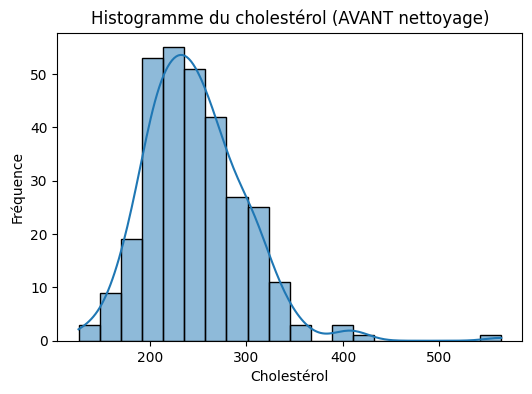

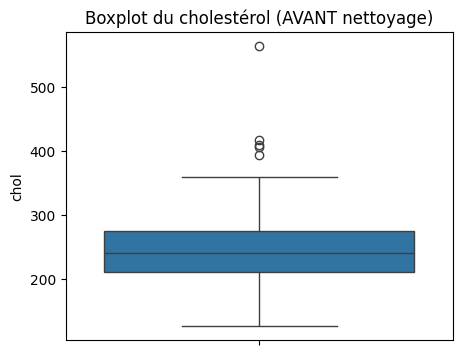

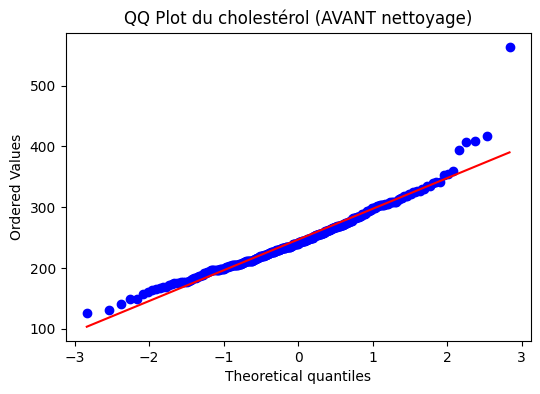

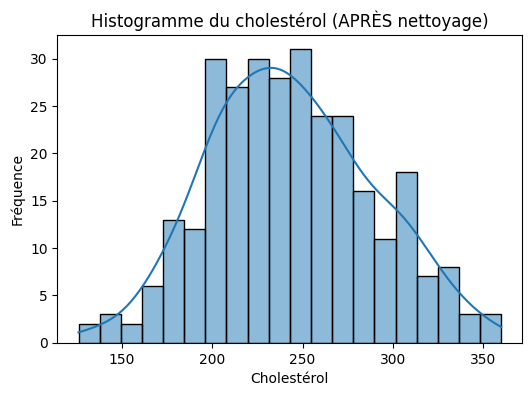

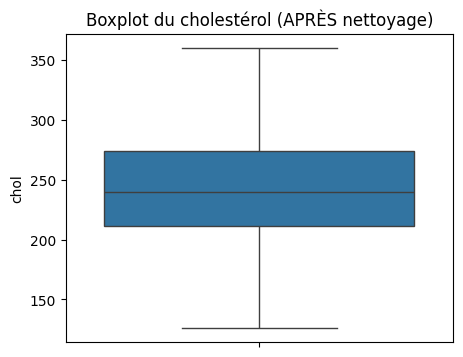

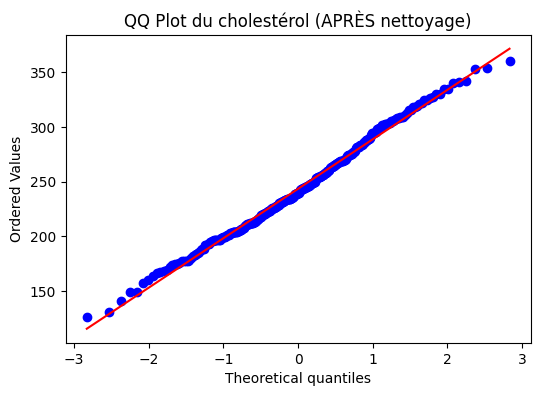

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# VISUALISATIONS AVANT NETTOYAGE

# Histogramme (avec fréquences)
plt.figure(figsize=(6,4))
sns.histplot(df['chol'], kde=True, bins=20)
plt.title("Histogramme du cholestérol (AVANT nettoyage)")
plt.xlabel("Cholestérol")
plt.ylabel("Fréquence")
plt.show()

#  Boxplot
plt.figure(figsize=(5,4))
sns.boxplot(y=df['chol'])
plt.title("Boxplot du cholestérol (AVANT nettoyage)")
plt.show()

# QQ Plot
plt.figure(figsize=(6,4))
stats.probplot(df['chol'], dist="norm", plot=plt)
plt.title("QQ Plot du cholestérol (AVANT nettoyage)")
plt.show()


# VISUALISATIONS APRÈS NETTOYAGE



#  Histogramme (avec fréquences)
plt.figure(figsize=(6,4))
sns.histplot(df_chol_clean['chol'], kde=True, bins=20)
plt.title("Histogramme du cholestérol (APRÈS nettoyage)")
plt.xlabel("Cholestérol")
plt.ylabel("Fréquence")
plt.show()

#  Boxplot
plt.figure(figsize=(5,4))
sns.boxplot(y=df_chol_clean['chol'])
plt.title("Boxplot du cholestérol (APRÈS nettoyage)")
plt.show()

# QQ Plot
plt.figure(figsize=(6,4))
stats.probplot(df_chol_clean['chol'], dist="norm", plot=plt)
plt.title("QQ Plot du cholestérol (APRÈS nettoyage)")
plt.show()


Avant nettoyage, la distribution du cholestérol présente une asymétrie positive importante avec plusieurs valeurs extrêmes élevées (outliers au-delà de 400 mg/dL) visibles sur le boxplot. Le QQ-plot montre des déviations marquées aux extrémités supérieures, indiquant une non-normalité. Après nettoyage des outliers, la distribution devient plus symétrique et proche d'une loi normale, centrée autour de 240 mg/dL avec une médiane similaire. Le QQ-plot après nettoyage montre un excellent alignement des points le long de la droite théorique, confirmant la normalité des données. Cette étape de nettoyage améliore considérablement la qualité des données et permet l'utilisation de tests paramétriques pour les analyses statistiques ultérieures.

# Analyse bivariée



---



INTRODUCTION :

L’objectif de cette analyse bivariée est d’étudier les relations entre les variables explicatives (prédicteurs) et entre chaque variable explicative et la variable à expliquer (Y).
La variable Y que nous étudions est target, qui indique la présence ou non d’une maladie cardiaque chez un patient (binaire : 0 = absence, 1 = présence).Dans cette partie, nous étudions uniquement les variables quantitatives : age, trestbps (pression artérielle systolique au repos), et chol (cholestérol sérique).

REMARQUES !!!! :

- La variable sex n’est pas incluse ici car elle est catégorielle. Pearson et les scatterplots sont adaptés aux variables quantitatives uniquement.


- Chi² vs ANOVA pour sex vs Y :

Pour deux variables catégorielles, le Chi² est le test standard.

L’ANOVA est calculée pour information, mais n’est pas appropriée pour ce cas.

- Transformations sur les variables quantitatives :

Testées pour vérifier si la linéarité pouvait être améliorée.

Résultat : transformations inutiles dans notre dataset.

- Variable cible :

target est la variable à expliquer (Y), indiquant la présence ou non de maladie cardiaque.

Chi²: categorical vs categorical.

ANOVA: quantitative vs categorical (2 or more groups).

In [ ]:
# Imports
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import boxcox
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram

# Load dataset
DATA_PATH = "/content/Heart_disease_cleveland.csv"  # Ajuster si nécessaire
df = pd.read_csv(DATA_PATH)

# Variables
quant_vars = ["age", "trestbps", "chol"]
cat_var = "sex"
target = "target"

print("Dataset loaded. Preview:")
print(df.head())


Dataset loaded. Preview:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   0       145   233    1        2      150      0      2.3      2   
1   67    1   3       160   286    0        2      108      1      1.5      1   
2   67    1   3       120   229    0        2      129      1      2.6      1   
3   37    1   2       130   250    0        0      187      0      3.5      2   
4   41    0   1       130   204    0        2      172      0      1.4      0   

   ca  thal  target  
0   0     2       0  
1   3     1       1  
2   2     3       1  
3   0     1       0  
4   0     1       0  


Corrélation de Pearson et scatterplots ET transformationS


=== age vs trestbps ===
Pearson correlation: r = 0.2849, p = 4.5e-07


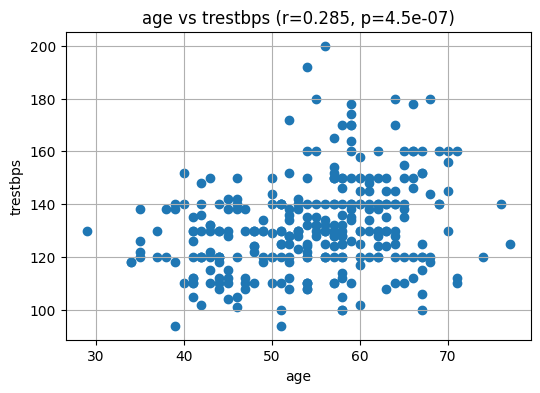

Log-log Pearson: r=0.2806, p=6.9e-07
Sqrt-sqrt Pearson: r=0.2840, p=5e-07
Box-Cox Pearson: r=0.2758, p=1.1e-06, λ_x=1.430, λ_y=-0.695

=== age vs chol ===
Pearson correlation: r = 0.2090, p = 0.00025


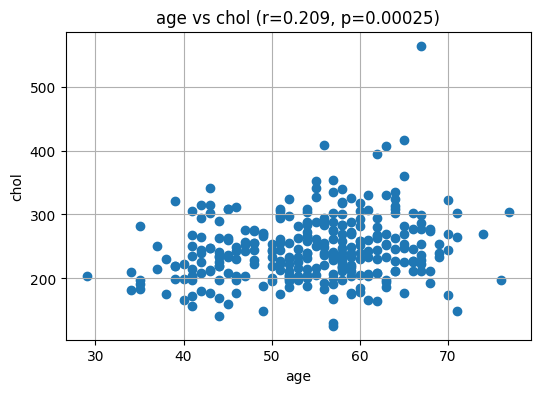

Log-log Pearson: r=0.2093, p=0.00024
Sqrt-sqrt Pearson: r=0.2100, p=0.00023
Box-Cox Pearson: r=0.1989, p=0.0005, λ_x=1.430, λ_y=-0.095

=== trestbps vs chol ===
Pearson correlation: r = 0.1301, p = 0.023


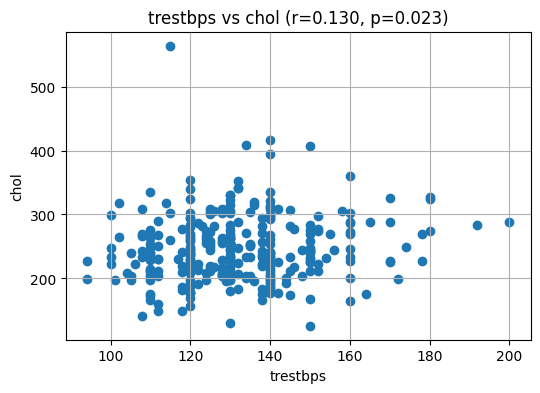

Log-log Pearson: r=0.1367, p=0.017
Sqrt-sqrt Pearson: r=0.1350, p=0.019
Box-Cox Pearson: r=0.1356, p=0.018, λ_x=-0.695, λ_y=-0.095


In [ ]:
# Helper for Pearson
def pearson_pair(x, y):
    r, p = stats.pearsonr(x, y)
    return r, p

# pairwise quantitative
pairs = [("age", "trestbps"), ("age", "chol"), ("trestbps", "chol")]

for v1, v2 in pairs:
    print(f"\n=== {v1} vs {v2} ===")
    x = df[v1]
    y = df[v2]

    # 1) Pearson correlation
    r, p = pearson_pair(x, y)
    print(f"Pearson correlation: r = {r:.4f}, p = {p:.2g}")

    # 2) Scatterplot
    plt.figure(figsize=(6,4))
    plt.scatter(x, y)
    plt.title(f"{v1} vs {v2} (r={r:.3f}, p={p:.2g})")
    plt.xlabel(v1)
    plt.ylabel(v2)
    plt.grid(True)
    plt.show()

    # 3) Transformations (log, sqrt, boxcox)
    # Log
    try:
        x_log = np.log(x + 1e-6)
        y_log = np.log(y + 1e-6)
        r_log, p_log = pearson_pair(x_log, y_log)
        print(f"Log-log Pearson: r={r_log:.4f}, p={p_log:.2g}")
    except:
        print("Log transform not applicable")

    # Sqrt
    try:
        x_sqrt = np.sqrt(x.clip(lower=0))
        y_sqrt = np.sqrt(y.clip(lower=0))
        r_sqrt, p_sqrt = pearson_pair(x_sqrt, y_sqrt)
        print(f"Sqrt-sqrt Pearson: r={r_sqrt:.4f}, p={p_sqrt:.2g}")
    except:
        print("Sqrt transform not applicable")

    # Box-Cox
    try:
        x_bc, lam_x = boxcox(x + 1e-6)
        y_bc, lam_y = boxcox(y + 1e-6)
        r_bc, p_bc = stats.pearsonr(x_bc, y_bc)
        print(f"Box-Cox Pearson: r={r_bc:.4f}, p={p_bc:.2g}, λ_x={lam_x:.3f}, λ_y={lam_y:.3f}")
    except:
        print("Box-Cox transform not applicable")


1. Coefficient de corrélation de Pearson (r)

Le coefficient r mesure la force et la direction d’une relation linéaire entre deux variables quantitatives.

Les valeurs varient de -1 à 1 :

r > 0 → corrélation positive (lorsqu’une variable augmente, l’autre tend à augmenter).

r < 0 → corrélation négative (lorsqu’une variable augmente, l’autre tend à diminuer).

r ≈ 0 → peu ou pas de corrélation linéaire.

Exemples issus de vos résultats :

age vs trestbps : r ≈ 0,28 → corrélation positive modérée.

age vs chol : r ≈ 0,21 → corrélation positive faible.

2. Valeur p (p-value, p)

La valeur p indique si la corrélation observée est statistiquement significative ou si elle pourrait être due au hasard.

Petite valeur p (p < 0,05) → corrélation significative.

Grande valeur p (p ≥ 0,05) → corrélation non significative.

Dans vos résultats :

age vs trestbps : p ≈ 6,9e-07 → très significatif.

age vs chol : p ≈ 0,00025 → significatif.

Pairs étudiées :

age ↔ trestbps

age ↔ chol

trestbps ↔ chol

Interprétations :

age vs trestbps : r ≈ 0,285, p < 0,001

Corrélation positive modérée. Les patients plus âgés tendent à avoir une pression artérielle systolique légèrement plus élevée.

Le scatterplot montre une relation linéaire modérée.

age vs chol : r ≈ 0,209, p < 0,001

Corrélation positive faible à modérée. L’âge et le cholestérol sont légèrement liés.

Les scatterplots indiquent que la relation est essentiellement linéaire, avec quelques points extrêmes.

trestbps vs chol : r ≈ 0,130, p ≈ 0,023

Corrélation faible. Peu de lien entre la pression artérielle et le cholestérol.

Scatterplot montre une relation très diffuse.

Pour linéariser les relations, nous avons testé le logarithme, la racine carrée et la transformation Box-Cox lorsque cela était possible. Aucune de ces transformations n’a significativement amélioré la corrélation, la relation linéaire brute restant la meilleure représentation des données.

RQUE !

Les transformations comme la racine carrée (sqrt), le logarithme et Box-Cox ont été appliquées pour essayer de linéariser les relations qui ne sont pas parfaitement linéaires.

L’objectif était de voir si ces transformations pouvaient augmenter la corrélation, c’est-à-dire rendre la relation plus linéaire et plus facile à modéliser.

Par exemple, certaines relations peuvent être exponentielles ou avoir des valeurs très dispersées ; ces transformations permettent de réduire l’écart et de rendre la tendance plus claire.

Dans notre dataset, aucune de ces transformations n’a amélioré significativement la corrélation, donc la relation linéaire brute restait la meilleure.

**Analyse des sous-groupes de variables explicatives (clustering)**

pk cette analyse ? On a fait une analyse de sous-groupes avec un clustering hiérarchique pour voir si certaines variables explicatives étaient fortement corrélées entre elles et formaient des groupes distincts. Cela permet de détecter des patterns ou des clusters de variables liées, ce qui peut être utile pour simplifier le modèle ou identifier des relations importantes. Ici, le résultat montre qu’il n’y a pas de sous-groupes forts, mais que age et trestbps sont un peu plus liés.

Absolute correlation matrix:
            age  trestbps   chol
age       1.000     0.285  0.209
trestbps  0.285     1.000  0.130
chol      0.209     0.130  1.000


/tmp/ipython-input-4156712348.py:8: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage_matrix = linkage(dist, method='average')


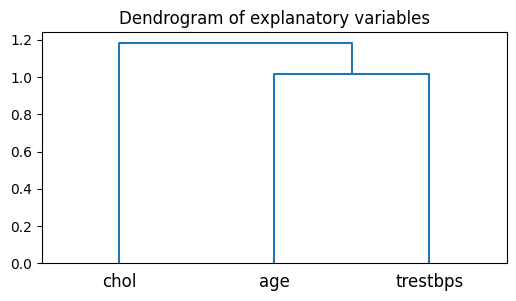

In [ ]:
# Absolute correlation matrix
corr_abs = df[quant_vars].corr().abs()
print("Absolute correlation matrix:")
print(corr_abs.round(3))

# Hierarchical clustering
dist = 1 - corr_abs.values
linkage_matrix = linkage(dist, method='average')
plt.figure(figsize=(6,3))
dendrogram(linkage_matrix, labels=quant_vars)
plt.title("Dendrogram of explanatory variables")
plt.show()


Les variables age, trestbps, et chol ne forment pas de sous-groupes fortement distincts.



Interpretation :

Nous avons analysé les sous-groupes de variables explicatives en calculant la matrice des corrélations absolues et en réalisant un clustering hiérarchique. Les résultats montrent qu’aucune sous-classe n’est fortement séparée. On remarque toutefois que l’âge et la tension artérielle au repos (trestbps) présentent une corrélation légèrement plus marquée que les autres variables. Dans l’ensemble, les trois variables forment un groupe cohérent sans sous-groupes distincts.

**Entre la variable à expliquer Y (target) et les variables explicatives**

Corrélation de Pearson (quantitatives) et Test de Student (t-test) pour les variables quantitatives


=== age vs target ===
Pearson correlation: r=0.2231, p=9e-05
t-test: mean(Y=0)=52.59, mean(Y=1)=56.63, t=-4.030, p=7.1e-05


/tmp/ipython-input-4070203553.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([g0, g1], labels=["Y=0","Y=1"])


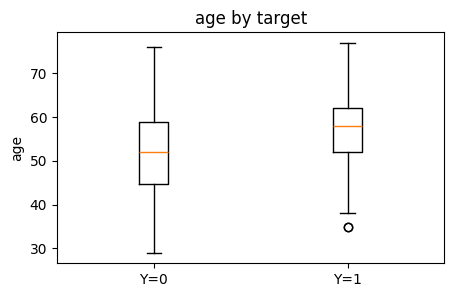


=== trestbps vs target ===
Pearson correlation: r=0.1508, p=0.0085
t-test: mean(Y=0)=129.25, mean(Y=1)=134.57, t=-2.615, p=0.0094


/tmp/ipython-input-4070203553.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([g0, g1], labels=["Y=0","Y=1"])


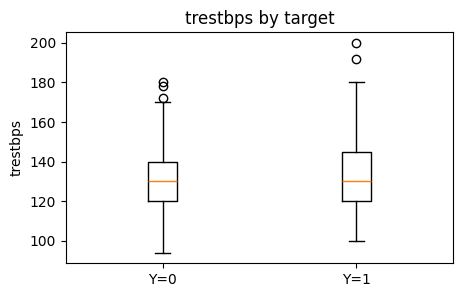


=== chol vs target ===
Pearson correlation: r=0.0852, p=0.14
t-test: mean(Y=0)=242.64, mean(Y=1)=251.47, t=-1.492, p=0.14


/tmp/ipython-input-4070203553.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([g0, g1], labels=["Y=0","Y=1"])


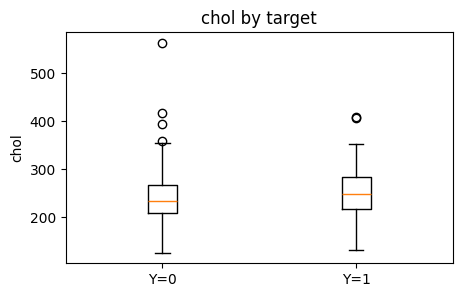

In [ ]:
for v in quant_vars:
    x = df[v]
    y = df[target]

    print(f"\n=== {v} vs target ===")
    # 1) Pearson correlation
    r, p = pearson_pair(x, y)
    print(f"Pearson correlation: r={r:.4f}, p={p:.2g}")

    # 3) Student t-test
    g0 = df[df[target]==0][v]
    g1 = df[df[target]==1][v]
    tstat, tp = stats.ttest_ind(g0, g1, equal_var=False)
    print(f"t-test: mean(Y=0)={g0.mean():.2f}, mean(Y=1)={g1.mean():.2f}, t={tstat:.3f}, p={tp:.2g}")

    # Boxplot
    plt.figure(figsize=(5,3))
    plt.boxplot([g0, g1], labels=["Y=0","Y=1"])
    plt.title(f"{v} by target")
    plt.ylabel(v)
    plt.show()


age : corrélation positive et t-test significatif → patients plus âgés plus souvent malades.

trestbps : corrélation positive modérée, t-test significatif → pression légèrement plus élevée chez Y=1.

chol : corrélation faible, t-test non significatif → cholestérol peu discriminant pour Y.

**variable catégorielle sex vs Y (Analyse pour la variable catégorielle sex)**

In [ ]:
# Contingency table
cont = pd.crosstab(df[cat_var], df[target])
print("Contingency (sex x target):")
print(cont)

# ANOVA (optionnel)
group0 = df[df[target]==0][cat_var]
group1 = df[df[target]==1][cat_var]
fstat, fp = stats.f_oneway(group0, group1)
print(f"ANOVA (sex ~ target): F={fstat:.4f}, p={fp:.2g}")

# Chi-squared
chi2, chi_p, dof, exp = stats.chi2_contingency(cont)
print(f"Chi-squared test: χ²={chi2:.4f}, p={chi_p:.2g}")


Contingency (sex x target):
target   0    1
sex            
0       72   25
1       92  114
ANOVA (sex ~ target): F=24.9789, p=9.9e-07
Chi-squared test: χ²=22.0426, p=2.7e-06


L’analyse montre une association significative entre le sexe et la présence de maladie cardiaque (Chi² ≈ 22,04, p < 0,001). Les hommes sont plus souvent malades que les femmes. L’ANOVA a été calculée à titre informatif, mais le test du Chi² reste la méthode appropriée pour ces variables catégorielles.

**La significativité**

L’étape de la significativité sert à déterminer quelles variables ont un effet réel sur la variable cible (Y) et lesquelles n’ont pas d’impact statistiquement significatif.
Autrement dit, elle permet de repérer les variables importantes à inclure dans un modèle prédictif et de ne pas se baser sur des variables qui ne discriminent pas le résultat.

In [ ]:
print("Significance summary (α=0.05):")
for v in quant_vars:
    g0 = df[df[target]==0][v]
    g1 = df[df[target]==1][v]
    tstat, tp = stats.ttest_ind(g0, g1, equal_var=False)
    sig = "significant" if tp < 0.05 else "not significant"
    print(f"{v}: t-test p={tp:.2g} -> {sig}")

sig_sex = "significant" if chi_p < 0.05 else "not significant"
print(f"sex: chi2 p={chi_p:.2g} -> {sig_sex}")


Significance summary (α=0.05):
age: t-test p=7.1e-05 -> significant
trestbps: t-test p=0.0094 -> significant
chol: t-test p=0.14 -> not significant
sex: chi2 p=2.7e-06 -> significant


Les variables age, trestbps et sex sont significativement associées à la variable cible, tandis que chol ne l’est pas. Les relations entre les variables explicatives sont globalement faibles à modérées et aucun sous-groupe distinct n’a été identifié. Cette analyse bivariée permet ainsi de repérer les variables les plus pertinentes à inclure dans une analyse multivariée ultérieure, comme une régression logistique.

Conclusion :

L’analyse bivariée montre des corrélations modérées entre age et trestbps, tandis que les autres relations entre variables explicatives restent faibles et aucun sous-groupe distinct n’a été détecté. Par rapport à la variable cible Y, les variables significatives sont age, trestbps et sex, alors que chol n’est pas significative. Ces résultats permettent d’identifier les variables les plus discriminantes pour le diagnostic et servent de base à la sélection de prédicteurs dans des modèles multivariés, tels que la régression logistique ou les méthodes de classification, en mettant en évidence les relations principales et la pertinence de chaque variable explicative.